# Note
- 深度學習是訓練機器的直覺，並非知識學習。
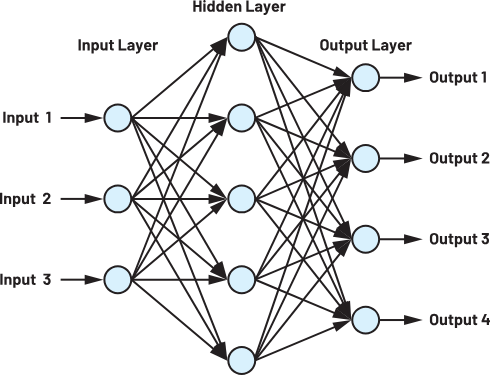

- 手寫辨識 Mnist dataset
- 半監督式學習 => 少量標籤資料 與 大量無標籤資料 訓練模型。
- 微積分-極值 => 意味著在 local 內 slope 為 0 的點
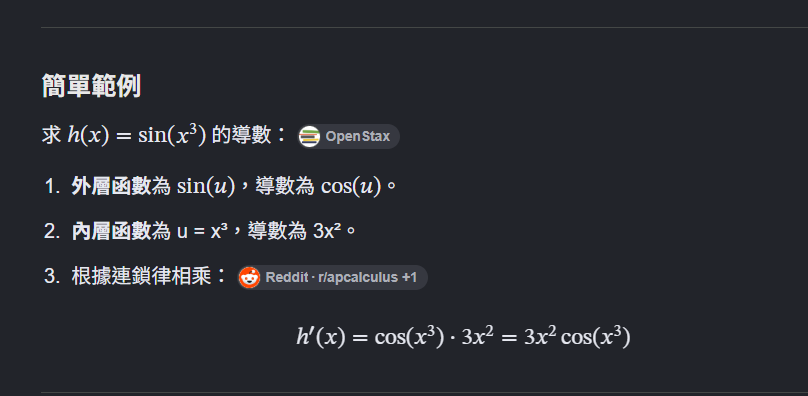
Loss Function 


In [11]:
import numpy as np

x = np.array(10.5)
print(x)
print(x.ndim)

x = np.array([1.2, 5.5, 8.7, 10.5])
print(x)
print(x.ndim)

x = np.array([
        [1.2, 5.5, 8.7, 10.5],
        [1.2, 5.5, 8.7, 10.5],
        [1.2, 5.5, 8.7, 10.5]])
print(x)
print(x.ndim)

y = np.array([
    [1,2,3],
    [4,5,6],
    [7,8,9],
    [10,11,12]
])
print(y)
print(y.ndim)

print(x.dot(y))

10.5
0
[ 1.2  5.5  8.7 10.5]
1
[[ 1.2  5.5  8.7 10.5]
 [ 1.2  5.5  8.7 10.5]
 [ 1.2  5.5  8.7 10.5]]
2
[[ 1  2  3]
 [ 4  5  6]
 [ 7  8  9]
 [10 11 12]]
2
[[189.1 215.  240.9]
 [189.1 215.  240.9]
 [189.1 215.  240.9]]


In [ ]:
import math

def q15_mul(a, b):
    r = int((a.real * b.real - a.imag * b.imag) / 32768)
    i = int((a.real * b.imag + a.imag * b.real) / 32768)
    clip = lambda x: max(-32768, min(32767, x))
    return complex(clip(r), clip(i))

N = 16
x = [complex(int(math.sin(2 * math.pi * 1 * (i / N)) * 32768), 0) for i in range(N)]
W = [complex(int(math.cos(2*math.pi*k/N) * 32768), int(-math.sin(2*math.pi*k/N) * 32768)) for k in range(N//2)]

for i in range(N):
    rev = int(f"{i:04b}"[::-1], 2) 
    if i < rev: x[i], x[rev] = x[rev], x[i]

stage = 1
while stage < N:
    for i in range(0, N, stage * 2):
        for j in range(stage):
            w = W[j * (N // (stage * 2))]
            even, odd = i + j, i + j + stage
            
            t = q15_mul(x[odd], w) 
            
            x[even], x[odd] = (x[even] + t) / 2, (x[even] - t) / 2
    stage *= 2

for i in range(N // 2):
    print(f"頻率點 {i}: 實部={int(x[i].real):>6}, 虛部={int(x[i].imag):>6}")


頻率點 0: 實部=     0, 虛部=     0
頻率點 1: 實部=     0, 虛部=-16382
頻率點 2: 實部=     0, 虛部=     0
頻率點 3: 實部=     0, 虛部=     0
頻率點 4: 實部=     0, 虛部=     0
頻率點 5: 實部=     0, 虛部=     0
頻率點 6: 實部=     0, 虛部=     0
頻率點 7: 實部=     0, 虛部=     0
